# 3.1 넘파이로 무작위 동전 뒤집기와 주사위 던지기 시뮬레이션

In [1]:
import matplotlib as mpl
from matplotlib import pyplot as plt

# 1. 폰트 설정 (Mac에서는 AppleGothic 사용)
mpl.rcParams['font.family'] = 'AppleGothic'

# 2. 마이너스(-) 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

In [2]:
# code 3-1 numpy import
import numpy as np

# code 3-2
# random으로 6개 중 1개의 숫자 설정
die_roll = np.random.randint(1, 7)
assert  1 <= die_roll <=6

In [3]:
# code 3-3 무자위로 얻은 주사위 값을 재현 가능하도록 시드 설정하기
np.random.seed(0) # ramdom 기준 설정
die_roll = [np.random.randint(1,7) for _ in range(3)]
print(die_roll)
assert die_roll == [5,6,1]

[5, 6, 1]


In [4]:
# code 3-4 공정한 뒤집기 한 번 시뮬레이션하기
np.random.seed(0)
coin_flip = np.random.randint(0,2)
print(f"동전은 {'앞면' if coin_flip == 1 else '뒷면'} 으로 나왔습니다")

동전은 뒷면 으로 나왔습니다


In [5]:
# code 3-4 10번 반복

count = 0
coin_flip_list = []
while count < 11:
    coin_flip = np.random.randint(0,2)
    print(f"동전은 {'앞면' if coin_flip == 1 else '뒷면'} 으로 나왔습니다")
    coin_flip_list.append(coin_flip)
    count += 1
print(f"앞면이 나올 확율은 {round(sum(coin_flip_list)/len(coin_flip_list) * 100,2)} % 입니다")

동전은 앞면 으로 나왔습니다
동전은 앞면 으로 나왔습니다
동전은 뒷면 으로 나왔습니다
동전은 앞면 으로 나왔습니다
동전은 앞면 으로 나왔습니다
동전은 앞면 으로 나왔습니다
동전은 앞면 으로 나왔습니다
동전은 앞면 으로 나왔습니다
동전은 앞면 으로 나왔습니다
동전은 앞면 으로 나왔습니다
동전은 뒷면 으로 나왔습니다
앞면이 나올 확율은 81.82 % 입니다


In [15]:
# code 3-5 동전 뒤집기 10번 시뮬레이션 하기
np.random.seed(0)
def frequency_heads(coin_flip_sequence):
    total_heads = len([head for head in coin_flip_sequence if head ==1])
    return total_heads / len(coin_flip_sequence)

coin_flip = [np.random.randint(0,2) for _ in range(10)]
freq_heads = frequency_heads(coin_flip)
print(f"동전 앞면이 관측될 빈도는 {freq_heads} 입니다")

동전 앞면이 관측될 빈도는 0.8 입니다


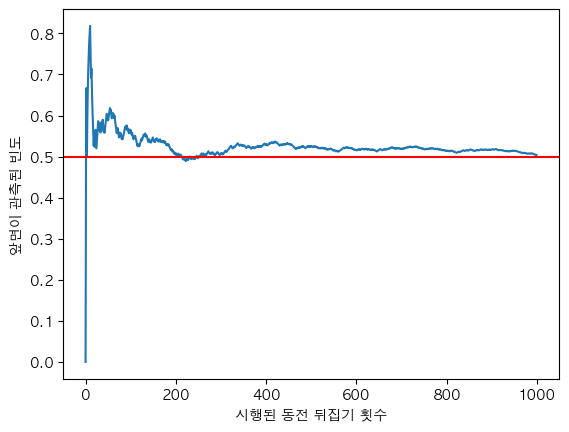

In [16]:
# code3-6 앞면의 공정한 동전 뒤집기 시물레이션 그래프
np.random.seed(0)
coin_flips = []
frequencies = []
for _ in range(1000):
    coin_flips.append(np.random.randint(0,2))
    frequencies.append(frequency_heads(coin_flips))

plt.plot(list(range(1000)),frequencies)
plt.axhline(0.5, color='r')
plt.xlabel('시행된 동전 뒤집기 횟수')
plt.ylabel('앞면이 관측된 빈도')
plt.show()

In [17]:
# code 3-7 편향된 동전 뒤집기 시뮬레이션하기
np.random.seed(0)
print('동전을 한 번 뒤집어 봅니다')
coin_flip = np.random.binomial(1, 0.7)
print(f'편항된 동전은 {str(1)+' : 앞면' if coin_flip == 1 else 0} 으로 떨어졌습니다')

print('\n동전을 10번 뒤집어 봅니다')
number_count = 10
head_count = np.random.binomial(number_count, 0.7)
print((f"{number_count} 번의 편향된 동전 뒤집기 중 앞면은"
       f"{head_count} 번 관측되었습니다"))

동전을 한 번 뒤집어 봅니다
편항된 동전은 1 : 앞면 으로 떨어졌습니다

동전을 10번 뒤집어 봅니다
10 번의 편향된 동전 뒤집기 중 앞면은6 번 관측되었습니다


In [18]:
# 3-8 동전 뒤집기 빈도의 수렴 정도 계산하기
np.random.seed(0)
head_count = np.random.binomial(1000, 0.7)
frequency = head_count / 1000
print(f'동전의 앞면이 관측될 빈도는 {frequency} 입니다')

동전의 앞면이 관측될 빈도는 0.697 입니다


In [19]:
# 3-9 동전 뒤집기 빈도의 수렴 정도 재 계산하기
np.random.seed(0)
assert np.random.binomial(1000, 0.7) / 1000 == 0.697
for i in range(1, 6):
    head_count = np.random.binomial(1000, 0.7)
    frequency = head_count / 1000
    print(f"{i}번째 반복에서의 빈도는 {frequency} 입니다")
    if frequency == 0.7:
        print('빈도의 실제 확률이 일치합니다 \n')

1번째 반복에서의 빈도는 0.69 입니다
2번째 반복에서의 빈도는 0.7 입니다
빈도의 실제 확률이 일치합니다 

3번째 반복에서의 빈도는 0.707 입니다
4번째 반복에서의 빈도는 0.702 입니다
5번째 반복에서의 빈도는 0.699 입니다


# 3.2 히스토그램과 넘파이 배열 계산하는 신뢰 구간

In [20]:
# code 3-10 동전 뒤집기 샘플링 1000번 500번 수행한 빈도 계산하기
np.random.seed(0)
head_count_list = [np.random.binomial(1000, 0.7) for _ in range(500)]

# code 3-11 동전 두집기 빈도 계산 최적화하기
np.random.seed(0)
head_count_array = np.random.binomial(1000, 0.7, 500)

# code 3-12 넘파이 배열을 파이썬 리스트로 변환하기
assert head_count_array.tolist() == head_count_list

# code 3-13 파이썬 리스트를 넘파이 배열로 변환하기
new_array = np.array(head_count_list)
assert np.array_equal(new_array, head_count_array) == 1

# code 3-14 넘파이로 빈도 계산하기
frequency_array = head_count_array / 1000
assert frequency_array.tolist() == [head_count / 1000 for head_count in head_count_list]
assert frequency_array.tolist() == list(map(lambda x: x / 1000, head_count_list))

# code 3-15 빈도를 담은 넘파이 배열 출력하기
print(frequency_array[:20])

[0.697 0.69  0.7   0.707 0.702 0.699 0.723 0.67  0.702 0.713 0.721 0.689
 0.711 0.697 0.717 0.691 0.731 0.697 0.722 0.728]


In [21]:
# code 3-16 최대 및 최소 빈도값 찾기
min_freq = frequency_array.min()
max_freq = frequency_array.max()
print(f"관측된 최소 빈도 : {min_freq}")
print(f"관측된 최대 빈도 : {max_freq}")
print(f"관측된 빈도의 범위 : {max_freq-min_freq}")

관측된 최소 빈도 : 0.656
관측된 최대 빈도 : 0.733
관측된 빈도의 범위 : 0.07699999999999996


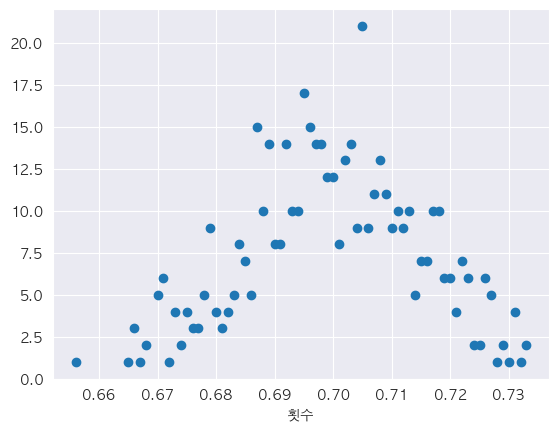

In [26]:
from collections import defaultdict

frequency_counts = defaultdict(int)
for frequency in frequency_array:
    frequency_counts[frequency] += 1

frequencies = list(frequency_counts.keys())
counts = [frequency_counts[freq] for freq in frequencies]

plt.scatter(frequencies, counts)
plt.xlabel('빈도')
plt.ylabel('횟수')
plt.show()

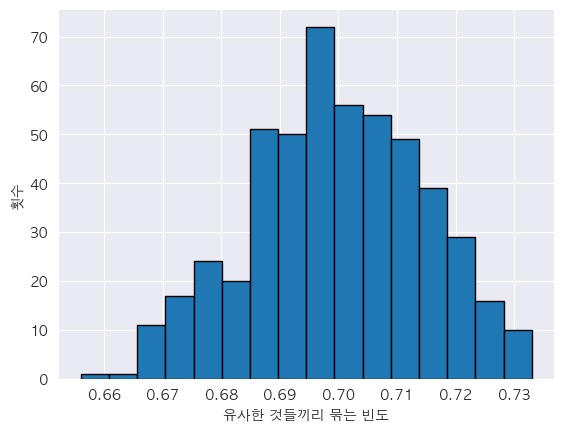

In [27]:
# code 3-18 plt.list를 사용한 빈도 히스토그램 그리기
plt.hist(frequency_array, bins='auto', edgecolor='k')
plt.xlabel('유사한 것들끼리 묶는 빈도')
plt.ylabel('횟수')
plt.show()

빈의 개수 : 16


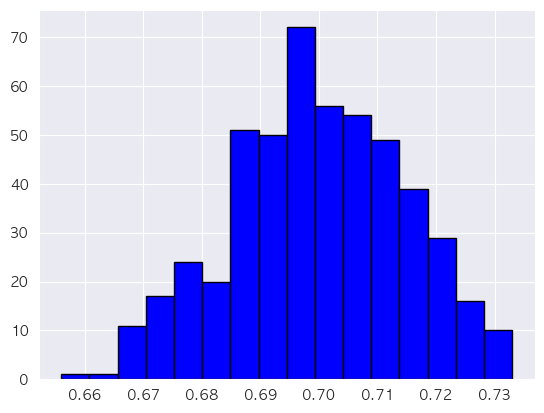

In [32]:
# code 3-19 히스토그램 빈 갯수
counts ,_,_=plt.hist(frequency_array, bins='auto', edgecolor='k', color='blue')
print(f'빈의 개수 : {counts.size}')

빈의 너비 : 0.004812499999999997


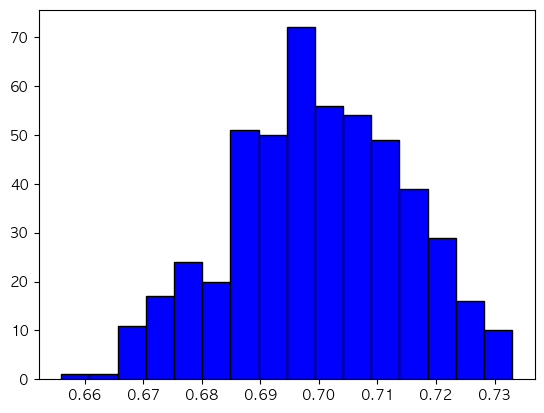

In [22]:
# code 3-20
counts ,bin_edges,_=plt.hist(frequency_array, bins='auto', edgecolor='k', color='blue')
bin_width = bin_edges[1] - bin_edges[0]
assert bin_width == (max_freq - min_freq) / counts.size
print(f"빈의 너비 : {bin_width}")

In [23]:
# code 3-21 빈의 빈도와 크기
def output_bin_coverage(i):
    count = int(counts[i])
    range_start, range_end = bin_edges[i], bin_edges[i+1]
    range_string = f"{range_start}-{range_end}"
    print((f"빈의 범위 : {range_string}에 대한 빈은 "
           f"{count}개의 요소를 포함합니다"))

for i in range(count):
    output_bin_coverage(i)

빈의 범위 : 0.656-0.6608125에 대한 빈은 1개의 요소를 포함합니다
빈의 범위 : 0.6608125-0.665625에 대한 빈은 1개의 요소를 포함합니다
빈의 범위 : 0.665625-0.6704375에 대한 빈은 11개의 요소를 포함합니다
빈의 범위 : 0.6704375-0.67525에 대한 빈은 17개의 요소를 포함합니다
빈의 범위 : 0.67525-0.6800625에 대한 빈은 24개의 요소를 포함합니다
빈의 범위 : 0.6800625-0.684875에 대한 빈은 20개의 요소를 포함합니다
빈의 범위 : 0.684875-0.6896875에 대한 빈은 51개의 요소를 포함합니다
빈의 범위 : 0.6896875-0.6945에 대한 빈은 50개의 요소를 포함합니다
빈의 범위 : 0.6945-0.6993125에 대한 빈은 72개의 요소를 포함합니다
빈의 범위 : 0.6993125-0.704125에 대한 빈은 56개의 요소를 포함합니다
빈의 범위 : 0.704125-0.7089375에 대한 빈은 54개의 요소를 포함합니다


In [39]:
# code 3-22 배열의 최대값에 대한 인덱스 구하기
assert counts[counts.argmax()] == counts.max()

In [40]:
output_bin_coverage(counts.argmax())

빈의 범위 : 0.6945-0.6993125에 대한 빈은 72개의 요소를 포함합니다


## 3.2.2 히스트그램에서 확률 구하기

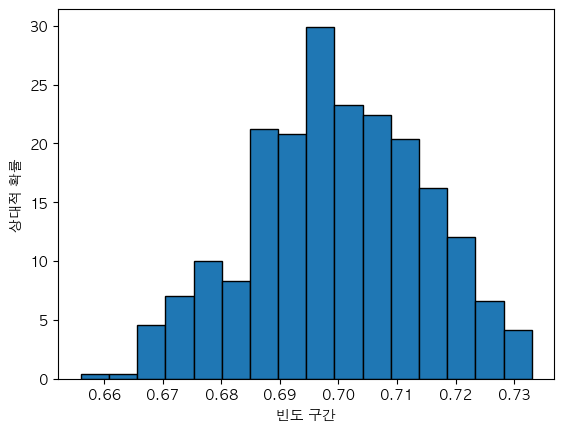

In [25]:
# code 3-24 히스토그램의 상대적 확률 그리기
likelihoods, bin_edges , _ = plt.hist(frequency_array, bins='auto', edgecolor='k', density=True)
plt.xlabel('빈도 구간')
plt.ylabel('상대적 확률')
plt.show()

In [26]:
# code 3-25 히스토그램의 전체 영역 계산하기
assert likelihoods.sum() * bin_width == 1

In [28]:
# code 3 -26 최고점 빈도에 대한 확률 계산하기
index = likelihoods.argmax()
area = likelihoods[index] * bin_width
range_start, range_end = bin_edges[index], bin_edges[index+1]
range_string = f"{range_start}-{range_end}"
print(f"샘플링 빈도가 {range_string} 구간에 속할 확률은 {area} 입니다")


샘플링 빈도가 0.6945-0.6993125 구간에 속할 확률은 0.144 입니다


In [29]:
# code 3-27 빈도 범위의 확률 늘리기
peak_index = likelihoods.argmax()
start_index, end_index  = (peak_index-1, peak_index+2)
area = likelihoods[start_index : end_index+1].sum() * bin_width
range_start, range_end = bin_edges[start_index], bin_edges[end_index]
range_string = f"{range_start}-{range_end}"
print(f"샘플링된 빈도가 {range_string} 구간에 속할 확률은 {area} 입니다")


샘플링된 빈도가 0.6896875-0.704125 구간에 속할 확률은 0.464 입니다


In [1]:
# code 3-28 높은 신뢰 구간 계산하기
def compute_high_confidence_interval(likelihoods, bin_width):
    peak_index = likelihoods.argmax()
    area = likelihoods[peak_index] * bin_width
    start_index, end_index  = peak_index, peak_index + 1
    while area < 0.95:
        if start_index > 0:
            start_index -= 1
        if end_index < likelihoods.size-1:
            end_index += 1

        area = likelihoods[start_index : end_index+1].sum() * bin_width

    range_start, range_end = bin_edges[start_index], bin_edges[end_index]
    range_string = f"{range_start:.6f}-{range_end:.6f}"
    print((f"빈도 범위 {range_string} 는 {100 * area:.2f} % 신뢰 구간을 나타냅니다"))
    return start_index, end_index


In [2]:
compute_high_confidence_interval(likelihoods, bin_width)

NameError: name 'likelihoods' is not defined